In [1]:
`import torch
import torch.nn as nn

K = 5
dim_input = 1
dim_output = 1
model = nn.Sequential(
    nn.Linear(dim_input, K),  
    nn.ReLU(),  # nn.Tanh(), nn.Sigmoid()
    nn.Linear(K, dim_output)    
)
print(model)

Sequential(
  (0): Linear(in_features=1, out_features=5, bias=True)
  (1): ReLU()
  (2): Linear(in_features=5, out_features=1, bias=True)
)


In [2]:
K = 5
model = nn.Sequential(
    nn.Linear(1, K),   # w_k0 + w_k1 * x
    nn.Tanh(),         # activation g
    nn.Linear(K, 1)    # beta_0 + sum beta_k * g(...)
)
print(model)

# How many parameters do we have
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total Parameters: {total_params}")

Sequential(
  (0): Linear(in_features=1, out_features=5, bias=True)
  (1): Tanh()
  (2): Linear(in_features=5, out_features=1, bias=True)
)
Total Parameters: 16


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


rng = np.random.default_rng(1)
x = np.sort(rng.uniform(-3, 3, 200)).reshape(-1, 1)
y = np.sin(x).ravel() + rng.normal(0, 0.2, 200)

X_t = torch.tensor(x, dtype=torch.float32)
y_t = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)

torch.manual_seed(1)
model = nn.Sequential(
    nn.Linear(1, K),   # w_k0 + w_k1 * x
    nn.Tanh(),         # activation g
    nn.Linear(K, 1)    # beta_0 + sum beta_k * g(...)
)

loss_fn = nn.MSELoss() # binary: nn.BCEWithLogitsLoss()


def my_loss(pred, y):
    return torch.mean((y - pred) ** 2)

lr = 1e-1
epochs = 2000
opt = torch.optim.Adam(model.parameters(), lr=lr) # 0. set the learning rate
for _ in range(epochs):              # 0. set the epochs.
    opt.zero_grad()                  # 1. clear old gradients
    loss = loss_fn(model(X_t), y_t)  # 2. compute the loss
    loss.backward()                  # 3. compute the gradient
    opt.step()                       # 4. update the weights


/Users/hyeongjin/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


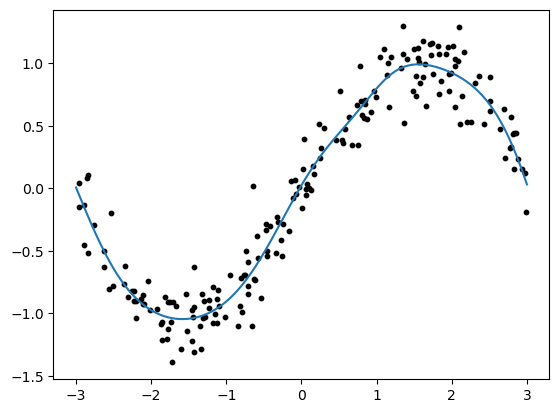

In [4]:
grid = np.linspace(-3, 3, 300).reshape(-1, 1)
grid_t = torch.tensor(grid, dtype=torch.float32)

plt.scatter(x, y, s=10, color='black')
with torch.no_grad():
        plt.plot(grid, model(grid_t).numpy())
plt.show()